# C02f — Controlled unique-word-share intervention
Exploratory follow-up to C02e2, on its **eight original AI texts**. One-word substitutions control the exact FZ-118 type–token ratio. No detector probabilities or contributions enter targeting, proposal, acceptance, or stopping. The original C02e2 files are read-only.

The primary outcome is distance to a frozen, length- and domain-matched training-human interval. Detector outcomes are secondary. This is a feasibility study, not evidence of population-wide humanization or an isolated causal effect of one feature. Lexical substitutions also alter recurrence and vocabulary composition.

Run top to bottom. The proposal cell uses the same GPT-4o-mini snapshot as C02e2 and requests an API key interactively. It makes at most **three proposal and three validation requests per case (48 total)**, with cached responses on rerun. No new responses are sampled for invalid or refused responses. No GPU is required. A fixed 5% word-edit budget limits changes; unreachable targets remain failures to reach the target.


In [1]:
from pathlib import Path
from collections import Counter
import json, hashlib, os, re, pickle, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

ROOT = Path('..')
BASE = ROOT / 'results/causal/C02d2_fz118_ghostbuster_raid'
PRIOR = ROOT / 'results/causal/C02e2_raid_feature_guided'
OUT = ROOT / 'results/causal/C02f_controlled_unique_word_share'
OUT.mkdir(parents=True, exist_ok=True)
C02D2_OUT = BASE
MODEL = 'gpt-4o-mini-2024-07-18'
CONFIG = dict(version='C02f_v1', model=MODEL, rounds=3, candidates_per_round=12,
              max_edit_fraction=0.05, max_edits=20, reference_neighbors=30,
              minimum_domain_humans=15, target_quantiles=[0.25, 0.75], seed=42)

def digest(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, ensure_ascii=False).encode()).hexdigest()

def write_json(path, value):
    tmp = path.with_suffix(path.suffix + '.tmp')
    tmp.write_text(json.dumps(value, indent=2, ensure_ascii=False))
    tmp.replace(path)

IMPLEMENTATION_HASH = 'a865cc4435772788bec974bf9da2ac7d757bed175f4f04061d6acee635c91415'


/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Exact C02e2 extractor
The following definitions are copied from C02e2. Install missing packages in the notebook kernel if prompted. The API client additionally requires `%pip install openai` if absent.


In [2]:
import importlib.util
required = {
    "spacy": "spacy",
    "textstat": "textstat",
    "sentence_transformers": "sentence-transformers",
    "pyarrow": "pyarrow",
    "requests": "requests",
}
missing = [
    pip_name
    for module, pip_name in required.items()
    if importlib.util.find_spec(module) is None
]
if missing:
    print("Run this once in the current kernel, restart, and rerun:")
    print("%pip install " + " ".join(sorted(set(missing))))
    raise RuntimeError("Missing packages: " + ", ".join(missing))

import requests
import spacy
import textstat

try:
    nlp = spacy.load("en_core_web_sm")
except OSError as exc:
    print("Run once, restart the kernel, and rerun:")
    print("!python -m spacy download en_core_web_sm")
    raise exc

PUNCTUATION = [
    ("comma", ","), ("period", "."), ("colon", ":"), ("semicolon", ";"),
    ("question", "?"), ("exclamation", "!"), ("hyphen", "-"),
    ("quote", '"'), ("lparen", "("), ("rparen", ")"),
    ("lbracket", "["), ("rbracket", "]"), ("newline", "\n"),
]

GOOGLE_WORDS_PATH = C02D2_OUT / "google-10000-english.txt"
GOOGLE_WORDS_URL = (
    "https://raw.githubusercontent.com/first20hours/"
    "google-10000-english/master/google-10000-english.txt"
)
if not GOOGLE_WORDS_PATH.exists():
    response = requests.get(GOOGLE_WORDS_URL, timeout=60)
    response.raise_for_status()
    GOOGLE_WORDS_PATH.write_bytes(response.content)

google_words = [
    line.strip().lower()
    for line in GOOGLE_WORDS_PATH.read_text(encoding="utf-8").splitlines()
    if line.strip()
]
GOOGLE_TOP = {
    100: set(google_words[:100]),
    1000: set(google_words[:1000]),
    10000: set(google_words[:10000]),
}
print("dependencies ready")


dependencies ready


In [3]:
def safe_div(a, b):
    return float(a) / float(b) if b else 0.0


def clean_word_tokens(span):
    return [
        token.text.lower()
        for token in span
        if token.is_alpha
    ]


def clean_pos_tokens(span):
    return [
        token.pos_
        for token in span
        if token.is_alpha
    ]


def ngram_counter(sequence, n):
    if len(sequence) < n:
        return Counter()
    return Counter(
        tuple(sequence[i:i+n])
        for i in range(len(sequence) - n + 1)
    )


def multiset_overlap(left, right, n):
    a = ngram_counter(left, n)
    b = ngram_counter(right, n)
    denominator = min(sum(a.values()), sum(b.values()))
    if denominator == 0:
        return 0.0
    shared = sum((a & b).values())
    return float(shared / denominator)


def overlap_histogram(sentences, token_fn, n):
    if len(sentences) < 2:
        return np.zeros(10, dtype=np.float64)

    values = [
        multiset_overlap(token_fn(left), token_fn(right), n)
        for left, right in zip(sentences[:-1], sentences[1:])
    ]

    # Include 1.0 in the final bin.
    bins = np.minimum((np.asarray(values) * 10).astype(int), 9)
    counts = np.bincount(bins, minlength=10).astype(np.float64)
    return counts / max(1, len(values))


def conjunction_overlap(sentences, n):
    values = []
    for sentence in sentences:
        words = clean_word_tokens(sentence)
        for i, word in enumerate(words):
            if word == "and":
                values.append(
                    multiset_overlap(words[:i], words[i+1:], n)
                )
    return float(np.mean(values)) if values else 0.0


def punctuation_count(text, symbol_name, symbol):
    if symbol_name == "quote":
        return text.count('"') + text.count("“") + text.count("”")
    return text.count(symbol)


def finite_readability(fn, text):
    try:
        value = float(fn(text))
        return value if np.isfinite(value) else 0.0
    except Exception:
        return 0.0


def extract_fz118(text):
    text = str(text)
    doc = nlp(text)
    sentences = [sent for sent in doc.sents if clean_word_tokens(sent)]
    words = [token.text.lower() for token in doc if token.is_alpha]

    n_characters = len(text)
    n_words = len(words)
    n_sentences = len(sentences)
    n_syllables = int(textstat.syllable_count(text))
    n_difficult = int(textstat.difficult_words(text))
    n_short = sum(len(word) <= 3 for word in words)
    n_long = sum(len(word) >= 7 for word in words)

    values = [
        n_characters,
        n_syllables,
        n_words,
        n_sentences,
        n_difficult,
        n_short,
        n_long,
        safe_div(n_characters, n_words),
        safe_div(n_syllables, n_words),
        safe_div(n_words, n_sentences),
        safe_div(n_difficult, n_words),
        safe_div(n_short, n_words),
        safe_div(n_long, n_words),
        finite_readability(textstat.automated_readability_index, text),
        finite_readability(textstat.coleman_liau_index, text),
        finite_readability(textstat.flesch_kincaid_grade, text),
        finite_readability(textstat.flesch_reading_ease, text),
        finite_readability(textstat.gunning_fog, text),
        finite_readability(textstat.lix, text),
        finite_readability(textstat.mcalpine_eflaw, text),
        finite_readability(textstat.rix, text),
        finite_readability(textstat.smog_index, text),
        safe_div(sum(token.is_stop for token in doc if token.is_alpha), n_words),
        safe_div(len(set(words)), n_words),
        safe_div(sum(word in GOOGLE_TOP[100] for word in words), n_words),
        safe_div(sum(word in GOOGLE_TOP[1000] for word in words), n_words),
        safe_div(sum(word in GOOGLE_TOP[10000] for word in words), n_words),
    ]

    punct_counts = [
        punctuation_count(text, name, symbol)
        for name, symbol in PUNCTUATION
    ]
    values += [safe_div(count, n_characters) for count in punct_counts]
    values += [safe_div(count, n_sentences) for count in punct_counts]

    paragraphs = [p.strip() for p in re.split(r"\n\s*\n", text) if p.strip()]
    paragraph_word_counts = [
        sum(token.is_alpha for token in nlp.make_doc(paragraph))
        for paragraph in paragraphs
    ]
    values += [
        len(paragraphs),
        float(np.mean(paragraph_word_counts)) if paragraph_word_counts else 0.0,
    ]

    for token_fn in [clean_word_tokens, clean_pos_tokens]:
        for n in [1, 2, 3]:
            values += overlap_histogram(sentences, token_fn, n).tolist()

    values += [conjunction_overlap(sentences, n) for n in [1, 2, 3]]

    vector = np.asarray(values, dtype=np.float64)
    assert vector.shape == (118,)
    assert np.isfinite(vector).all()
    return vector


toy = "One short sentence. Another sentence repeats one short phrase, and one short phrase returns."
toy_vector = extract_fz118(toy)
assert toy_vector.shape == (118,)
print("FZ-118 extractor smoke test passed")


FZ-118 extractor smoke test passed


## 2. Freeze the eight cases and human targets
Use training humans only. Select the 30 nearest humans in log alphabetic-word count within domain, requiring at least 15. If the domain lacks 15, use the 30 nearest training humans across domains and explicitly flag the fallback. The target is the reference interquartile interval, not a universal median. No target is selected using detector scores. Documents already inside the interval receive no treatment.

The immutable contract includes input text, reference IDs/ratios, targets, edit budgets, extractor source, and package versions. Changed inputs require a new output directory; existing artifacts are never silently repurposed.


In [4]:
import importlib.metadata as metadata
features = pd.read_parquet(BASE / 'fz118_paired_features.parquet')
corpus = pd.read_parquet(BASE / 'paired_corpus.parquet')
selection = pd.read_csv(PRIOR / 'raid_micro_selection.csv')
assert len(selection) == 8 and selection.source_id.is_unique
humans = features.loc[(features.dataset == 'raid') & (features.split == 'train') & (features.label == 0)].copy()
assert len(humans) >= CONFIG['reference_neighbors']
assert humans.source_id.is_unique and corpus.source_id.is_unique
text_map = corpus.set_index('source_id').text.to_dict()
with (BASE / 'fz118_feature_contract.json').open() as f:
    feature_contract = json.load(f)
FEATURE_NAMES = feature_contract['feature_names']

def normalize(text):
    return str(text).translate(str.maketrans({'\n': ' ', '\r': ' '}))

def counts(text):
    words = [t.text.lower() for t in nlp(text) if t.is_alpha]
    return len(set(words)), len(words)

frozen_cases = []
references = []
for case in selection.to_dict('records'):
    text = str(text_map[case['source_id']])
    v, w = counts(text)
    assert w > 0
    cached = features.loc[features.source_id == case['source_id']].iloc[0]
    assert np.allclose(extract_fz118(normalize(text)), cached[FEATURE_NAMES].to_numpy(float), atol=1e-9, rtol=0)
    pool = humans.loc[humans.domain == case['domain']].copy()
    fallback = len(pool) < CONFIG['minimum_domain_humans']
    if fallback: pool = humans.copy()
    pool['length_distance'] = abs(np.log(pool.n_words.clip(lower=1)) - np.log(w))
    ref = pool.sort_values(['length_distance', 'source_id']).head(CONFIG['reference_neighbors'])
    low, high = np.quantile(ref.share_unique_words, CONFIG['target_quantiles'])
    ratio = v / w
    direction = 'decrease' if ratio > high else 'increase' if ratio < low else 'none'
    needed = max(0, math.ceil(v-high*w-1e-10)) if direction == 'decrease' else max(0, math.ceil(low*w-v-1e-10)) if direction == 'increase' else 0
    budget = min(CONFIG['max_edits'], math.floor(CONFIG['max_edit_fraction']*w))
    frozen_cases.append(dict(case_id=case['case_id'], source_id=case['source_id'], domain=case['domain'],
        original=text, V=v, W=w, ratio=ratio, low=float(low), high=float(high), direction=direction,
        needed_edits=needed, budget=budget, reference_fallback=fallback, reference_n=len(ref)))
    references.extend(dict(case_id=case['case_id'], source_id=r.source_id, W=int(r.n_words), ratio=float(r.share_unique_words)) for r in ref.itertuples())
versions = {p: metadata.version(p) for p in ['spacy','textstat','numpy','pandas']}
contract = dict(config=CONFIG, cases=frozen_cases, references=references, versions=versions,
                spacy_model=nlp.meta, implementation_sha256=IMPLEMENTATION_HASH)
CONTRACT_HASH = digest(contract)
contract_path = OUT / 'frozen_contract.json'
if contract_path.exists():
    assert digest(json.loads(contract_path.read_text())) == CONTRACT_HASH, 'Contract changed: use a new output directory.'
else: write_json(contract_path, contract)
pd.DataFrame(references).to_csv(OUT / 'human_references.csv', index=False)
display(pd.DataFrame(frozen_cases).drop(columns=['original','source_id']))
print('Frozen contract:', CONTRACT_HASH)


,case_id,domain,V,W,ratio,low,high,direction,needed_edits,budget,reference_fallback,reference_n
0,raid_micro_01,recipes,129,249,0.518072,0.481328,0.541385,none,0,12,False,30
1,raid_micro_02,wiki,149,245,0.608163,0.519750,0.602648,decrease,2,12,False,30
2,raid_micro_03,reddit,79,107,0.738318,0.595468,0.670929,decrease,8,5,False,30
3,raid_micro_04,news,189,343,0.551020,0.528947,0.564485,none,0,17,False,30
4,raid_micro_05,reddit,93,158,0.588608,0.592174,0.642142,increase,1,7,False,30
5,raid_micro_06,books,137,270,0.507407,0.541293,0.596068,increase,10,13,False,30
6,raid_micro_07,poetry,172,238,0.722689,0.537912,0.625590,decrease,24,11,False,30
7,raid_micro_08,abstracts,63,111,0.567568,0.615342,0.666667,increase,6,5,False,30


Frozen contract: e64e46d4ed6c27a95d50d76ec51c2f12c418a70eb57d2e6c49c49c35c51c8101


## 3. Exact local edits and protection rules
Only single alphabetic-token replacements with identical POS and inflectional features are eligible. Punctuation, sentence order, whitespace, numbers, named entities, stopwords, and original proper nouns are protected. Replacements are not lemmatized. For decreasing TTR, the replaced word must be a singleton and the replacement must already exist. Increasing TTR requires a repeated source word and a new replacement type.

An independent validation request sees the original full passage and each proposed sentence substitution. It must explicitly approve contextual equivalence, grammar, tone, and technical terminology. This is an automated screen, not a factual-preservation guarantee; final edits remain available for manual review. Multiple changes within one sentence are not accepted, to limit interactions between independently checked proposals.


In [5]:
ALLOWED_POS = {'NOUN', 'VERB', 'ADJ', 'ADV'}

def distance(r, low, high):
    return max(low-r, 0.0, r-high)

def candidates_context(text, direction, blocked_sentences=()):
    doc = nlp(text)
    freq = Counter(t.text.lower() for t in doc if t.is_alpha)
    rows = []
    for t in doc:
        if not t.is_alpha or t.is_stop or t.ent_type_ or t.pos_ not in ALLOWED_POS:
            continue
        if t.sent.start in blocked_sentences: continue
        eligible = freq[t.text.lower()] == 1 if direction == 'decrease' else freq[t.text.lower()] >= 2
        if eligible:
            rows.append(dict(token_index=t.i, word=t.text, pos=t.pos_, sentence=t.sent.text))
    vocab = sorted({t.text.lower() for t in doc if t.is_alpha and not t.is_stop and not t.ent_type_ and t.pos_ in ALLOWED_POS})
    return rows, vocab

def attempt_edit(text, token_index, replacement, direction, low, high, blocked_sentences=()):
    doc = nlp(text)
    if not isinstance(token_index, int) or not 0 <= token_index < len(doc): return None, 'bad_index'
    t = doc[token_index]
    if t.sent.start in blocked_sentences: return None, 'sentence_already_edited'
    if not t.is_alpha or t.is_stop or t.ent_type_ or t.pos_ not in ALLOWED_POS: return None, 'protected_token'
    if not isinstance(replacement, str) or not replacement.isalpha(): return None, 'not_one_word'
    if replacement.lower() == t.text.lower(): return None, 'unchanged'
    freq = Counter(z.text.lower() for z in doc if z.is_alpha)
    if direction == 'decrease' and not (freq[t.text.lower()] == 1 and freq[replacement.lower()] > 0): return None, 'wrong_type_change'
    if direction == 'increase' and not (freq[t.text.lower()] >= 2 and freq[replacement.lower()] == 0): return None, 'wrong_type_change'
    replacement = replacement.upper() if t.text.isupper() else replacement.capitalize() if t.text.istitle() else replacement.lower()
    changed = text[:t.idx] + replacement + text[t.idx+len(t.text):]
    newdoc = nlp(changed)
    if len(newdoc) != len(doc): return None, 'tokenization_changed'
    nt = newdoc[token_index]
    if nt.pos_ != t.pos_ or str(nt.morph) != str(t.morph) or nt.is_stop or nt.ent_type_: return None, 'grammar_or_entity_changed'
    if [(s.start,s.end) for s in doc.sents] != [(s.start,s.end) for s in newdoc.sents]: return None, 'sentence_segmentation_changed'
    # Preserve all other token strings and entity spans, including model-detected entities.
    if any(a.text != b.text for i,(a,b) in enumerate(zip(doc,newdoc)) if i != token_index): return None, 'collateral_token_change'
    if [(e.text,e.label_) for e in doc.ents] != [(e.text,e.label_) for e in newdoc.ents]: return None, 'entity_signature_changed'
    v,w = counts(text); nv,nw = counts(changed)
    expected = -1 if direction == 'decrease' else 1
    if nw != w or nv-v != expected: return None, 'count_invariant_failed'
    if distance(nv/nw,low,high) >= distance(v/w,low,high)-1e-12: return None, 'no_target_improvement'
    return dict(text=changed, token_index=token_index, old=t.text, new=replacement,
                sentence_start=t.sent.start, before_sentence=t.sent.text, after_sentence=nt.sent.text,
                V_before=v,V_after=nv,W=w), 'eligible'


## 4. Cached proposal and validation calls
Responses are cached by exact messages, model, and frozen contract. A cached refusal or malformed response is retained and ends that round; it does not trigger replacement sampling. Detector scores are never supplied. All rejected proposals are logged. Accepted edits are considered in ascending token position, not ranked by a detector or a language-model likelihood.

This cell performs the authorized eight-case pilot when run. Existing completed case checkpoints are reused. Each case has at most three proposal rounds, with at most twelve candidates per round.


In [6]:
from openai import OpenAI
from getpass import getpass
CACHE = OUT / 'api_cache'
CACHE.mkdir(exist_ok=True)
_client = None

def ask_json(prompt):
    global _client
    request = dict(model=MODEL, temperature=0, response_format={'type':'json_object'},
                   messages=[{'role':'user','content':prompt}], max_tokens=3500)
    key = digest(dict(contract=CONTRACT_HASH, request=request))
    path = CACHE / (key + '.json')
    if path.exists():
        saved = json.loads(path.read_text())
        assert saved['request'] == request
    else:
        if _client is None:
            api_key = os.environ.get('OPENAI_API_KEY') or getpass('OpenAI API key: ')
            _client = OpenAI(api_key=api_key, max_retries=0, timeout=180)
        # Transport exceptions stop execution. Rerun to resume; never pick among responses.
        response = _client.chat.completions.create(**request)
        saved = dict(request=request, response=response.model_dump(mode='json'))
        write_json(path, saved)
    choice = saved['response']['choices'][0]
    if choice.get('finish_reason') != 'stop': return {}, key
    try: return json.loads(choice['message']['content']), key
    except (ValueError, TypeError): return {}, key

all_states = []
for case in tqdm(frozen_cases, desc='eight frozen cases'):
    path = OUT / (case['case_id'] + '_state.json')
    if path.exists():
        state = json.loads(path.read_text())
        assert state['contract_hash'] == CONTRACT_HASH
        assert state['state_hash'] == digest({k:v for k,v in state.items() if k != 'state_hash'})
    else:
        state = dict(contract_hash=CONTRACT_HASH, case_id=case['case_id'], text=case['original'],
                     next_round=0, accepted=[], audit=[], blocked_sentences=[])
    def checkpoint():
        state['state_hash'] = digest({k:v for k,v in state.items() if k != 'state_hash'})
        write_json(path, state)
    if case['direction'] == 'none':
        checkpoint(); all_states.append(state); continue
    for round_index in range(state['next_round'], CONFIG['rounds']):
        v,w = counts(state['text'])
        if distance(v/w,case['low'],case['high']) <= 1e-12 or len(state['accepted']) >= case['budget']: break
        eligible, vocab = candidates_context(state['text'],case['direction'],state['blocked_sentences'])
        if not eligible: break
        prompt = ('Propose local meaning-preserving one-word substitutions for a lexical diversity experiment. '
                  'Do not rewrite sentences. Preserve every proposition, degree, connotation, register, '
                  'technical meaning and entity. Do not replace specific terms with broader terms. '
                  'If no safe edit exists return an empty list. Return JSON {"edits":[{"token_index":integer,"replacement":"word"}]}. '
                  f'At most {CONFIG["candidates_per_round"]} edits, one per sentence. '
                  + ('Replacement must already occur in allowed_vocabulary.' if case['direction']=='decrease' else
                     'Replacement must be absent from the passage vocabulary; use a genuine contextual synonym.')
                  + '\n' + json.dumps(dict(full_passage=state['text'], eligible_positions=eligible, allowed_vocabulary=vocab),ensure_ascii=False))
        proposed, proposal_key = ask_json(prompt)
        proposals = proposed.get('edits',[]) if isinstance(proposed,dict) else []
        if not isinstance(proposals,list): proposals=[]
        checked=[]; seen=set()
        for item in proposals[:CONFIG['candidates_per_round']]:
            if not isinstance(item,dict): continue
            index=item.get('token_index'); replacement=item.get('replacement')
            if not isinstance(index,int) or index in seen: continue
            seen.add(index)
            edit,reason=attempt_edit(state['text'],index,replacement,case['direction'],case['low'],case['high'],state['blocked_sentences'])
            if edit: checked.append(edit)
            else: state['audit'].append(dict(round=round_index,token_index=index,replacement=replacement,status=reason,proposal_key=proposal_key))
        approved=set(); judge_key=None
        if checked:
            judge_prompt=('Validate each independent one-word substitution against the full passage. '
                'Approve only if meaning, factual claims, specificity, degree, technical sense, grammar and register are preserved. '
                'Reject ambiguity or uncertainty. Ignore lexical diversity; do not propose alternatives. '
                'Return JSON {"verdicts":[{"token_index":integer,"approved":boolean,"reason":"brief explanation"}]}.\n'
                +json.dumps(dict(full_passage=state['text'],edits=[{k:e[k] for k in ['token_index','old','new','before_sentence','after_sentence']} for e in checked]),ensure_ascii=False))
            verdicts,judge_key=ask_json(judge_prompt)
            verdict_list=verdicts.get('verdicts',[]) if isinstance(verdicts,dict) else []
            if not isinstance(verdict_list,list): verdict_list=[]
            verdict_counts=Counter(v.get('token_index') for v in verdict_list if isinstance(v,dict) and isinstance(v.get('token_index'),int))
            approved={v['token_index'] for v in verdict_list if isinstance(v,dict) and v.get('approved') is True and isinstance(v.get('token_index'),int) and verdict_counts.get(v.get('token_index'))==1}
        for e in sorted(checked,key=lambda e:e['token_index']):
            status='semantic_rejected'
            if e['token_index'] in approved and len(state['accepted']) < case['budget']:
                edit,status=attempt_edit(state['text'],e['token_index'],e['new'],case['direction'],case['low'],case['high'],state['blocked_sentences'])
                if edit:
                    state['text']=edit.pop('text')
                    state['blocked_sentences'].append(edit['sentence_start'])
                    state['accepted'].append(dict(round=round_index,**edit))
                    status='accepted'
            state['audit'].append(dict(round=round_index,token_index=e['token_index'],old=e['old'],new=e['new'],status=status,proposal_key=proposal_key,judge_key=judge_key))
        state['next_round']=round_index+1
        checkpoint()
    checkpoint()
    all_states.append(state)
print('Completed. No detector scores used.')


eight frozen cases:   0%|                                                                                             | 0/8 [00:00<?, ?it/s]

OpenAI API key:  ········


eight frozen cases: 100%|█████████████████████████████████████████████████████████████████████████████████████| 8/8 [01:46<00:00, 13.31s/it]

Completed. No detector scores used.


## 5. Freeze treatments, inspect feasibility and preservation
Target-hit rate is computed among initially out-of-range cases, not inflated by unchanged cases. All cases remain in the output, including budget exhaustion and no feasible edit. Manual review fields are deliberately blank; automated approval is not a human preservation judgment.


,case_id,domain,direction,W,V_before,V_after,ratio_before,ratio_after,low,high,distance_before,distance_after,n_edits,budget,target_hit,status
0,raid_micro_01,recipes,none,249,129,129,0.518072,0.518072,0.481328,0.541385,0.000000,0.000000,0,12,True,already_in_range
1,raid_micro_02,wiki,decrease,245,149,149,0.608163,0.608163,0.519750,0.602648,0.005515,0.005515,0,12,False,no_further_accepted_edit
2,raid_micro_03,reddit,decrease,107,79,79,0.738318,0.738318,0.595468,0.670929,0.067389,0.067389,0,5,False,no_further_accepted_edit
3,raid_micro_04,news,none,343,189,189,0.551020,0.551020,0.528947,0.564485,0.000000,0.000000,0,17,True,already_in_range
4,raid_micro_05,reddit,increase,158,93,94,0.588608,0.594937,0.592174,0.642142,0.003566,0.000000,1,7,True,target_hit
5,raid_micro_06,books,increase,270,137,143,0.507407,0.529630,0.541293,0.596068,0.033886,0.011664,6,13,False,no_further_accepted_edit
6,raid_micro_07,poetry,decrease,238,172,172,0.722689,0.722689,0.537912,0.625590,0.097099,0.097099,0,11,False,no_further_accepted_edit
7,raid_micro_08,abstracts,increase,111,63,63,0.567568,0.567568,0.615342,0.666667,0.047774,0.047774,0,5,False,no_further_accepted_edit


Initially outside reference interval: 6
Targets reached among those: 1
Cases with any accepted edit: 2


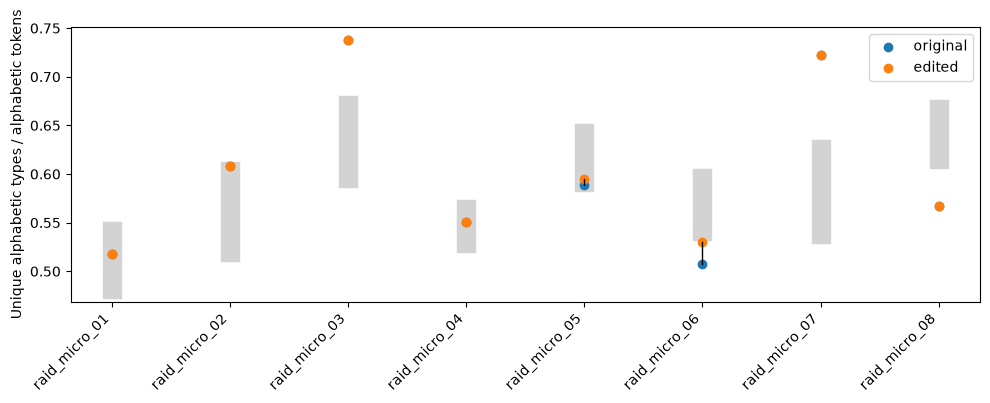

In [7]:
rows=[]; edit_rows=[]; audit_rows=[]
for case,state in zip(frozen_cases,all_states):
    v,w=counts(state['text'])
    assert w==case['W']
    original_doc=nlp(case['original']); final_doc=nlp(state['text'])
    allowed={e['token_index'] for e in state['accepted']}
    assert len(original_doc)==len(final_doc)
    assert all(a.text==b.text and a.whitespace_==b.whitespace_ for i,(a,b) in enumerate(zip(original_doc,final_doc)) if i not in allowed)
    hit=distance(v/w,case['low'],case['high'])<=1e-12
    rows.append(dict(case_id=case['case_id'],source_id=case['source_id'],domain=case['domain'],
        original=case['original'],treatment=state['text'],direction=case['direction'],W=w,V_before=case['V'],V_after=v,
        ratio_before=case['ratio'],ratio_after=v/w,low=case['low'],high=case['high'],
        distance_before=distance(case['ratio'],case['low'],case['high']),distance_after=distance(v/w,case['low'],case['high']),
        n_edits=len(state['accepted']),budget=case['budget'],target_hit=hit,
        status='already_in_range' if case['direction']=='none' else 'target_hit' if hit else 'budget_exhausted' if len(state['accepted'])>=case['budget'] else 'no_further_accepted_edit',
        manual_preservation='',manual_notes=''))
    edit_rows.extend(dict(case_id=case['case_id'],**e) for e in state['accepted'])
    audit_rows.extend(dict(case_id=case['case_id'],**e) for e in state['audit'])
results=pd.DataFrame(rows)
treatment_payload=dict(contract_hash=CONTRACT_HASH,treatments=rows)
freeze_path=OUT/'treatment_freeze.json'
if freeze_path.exists(): assert digest(json.loads(freeze_path.read_text()))==digest(treatment_payload)
else: write_json(freeze_path,treatment_payload)
results.to_csv(OUT/'treatments.csv',index=False)
pd.DataFrame(edit_rows).to_csv(OUT/'accepted_edits.csv',index=False)
pd.DataFrame(audit_rows).to_csv(OUT/'proposal_audit.csv',index=False)
display(results.drop(columns=['original','treatment','source_id','manual_notes','manual_preservation']))
needs=results.direction.ne('none')
print('Initially outside reference interval:',int(needs.sum()))
print('Targets reached among those:',int((needs & results.target_hit).sum()))
print('Cases with any accepted edit:',int(results.n_edits.gt(0).sum()))
# Regenerate safely without overwriting a completed human review.
review_path=OUT/'manual_review.csv'
if not review_path.exists(): results[['case_id','original','treatment','manual_preservation','manual_notes']].to_csv(review_path,index=False)
fig,ax=plt.subplots(figsize=(10,4))
for i,row in results.iterrows():
    ax.plot([i,i],[row.low,row.high],color='lightgray',linewidth=14,zorder=0)
    ax.plot([i,i],[row.ratio_before,row.ratio_after],color='black',linewidth=1)
ax.scatter(range(8),results.ratio_before,label='original')
ax.scatter(range(8),results.ratio_after,label='edited')
ax.set_xticks(range(8),results.case_id,rotation=45,ha='right')
ax.set_ylabel('Unique alphabetic types / alphabetic tokens'); ax.legend(); fig.tight_layout()
fig.savefig(OUT/'raw_ratio_movement.png',dpi=180)
plt.show()


## 6. Secondary detector and collateral outcomes, after treatment freeze
Load the exact frozen C02e2 detector; do not refit. Report every case, including no-edit cases. A reduction in detector score is not sufficient to establish surface-distribution equivalence. Raw changes are reported for all 118 features. All automated-valid results still require manual preservation review. This experiment does not compute U(k); that comes only after establishing a useful surface intervention.


In [8]:
assert digest(json.loads(freeze_path.read_text())) == digest(treatment_payload)
with (PRIOR/'fz118_raid_no_parentheses_detector.pkl').open('rb') as f: detector=pickle.load(f)
model_features=json.loads((PRIOR/'fz118_raid_model_features.json').read_text())
before=pd.DataFrame([extract_fz118(normalize(t)) for t in results.original],columns=FEATURE_NAMES)
after=pd.DataFrame([extract_fz118(normalize(t)) for t in results.treatment],columns=FEATURE_NAMES)
assert np.allclose(before.share_unique_words,results.ratio_before)
assert np.allclose(after.share_unique_words,results.ratio_after)
p0=detector.predict_proba(before[model_features])[:,1]
p1=detector.predict_proba(after[model_features])[:,1]
outcomes=results.drop(columns=['original','treatment']).copy()
outcomes['score_before']=p0; outcomes['score_after']=p1; outcomes['score_change']=p1-p0
ops=pd.read_csv(PRIOR/'raid_operating_points_p95_p99.csv')
for op in ops.itertuples():
    threshold=op.validation_human_threshold; name=f'p{round(op.human_specificity_target*100)}'
    outcomes[name+'_crossed_below']=(p0>=threshold)&(p1<threshold)
    outcomes[name+'_crossed_above']=(p0<threshold)&(p1>=threshold)
outcomes.to_csv(OUT/'secondary_detector_outcomes.csv',index=False)
collateral=[]
scale=humans[FEATURE_NAMES].quantile(.75)-humans[FEATURE_NAMES].quantile(.25)
for i,case_id in enumerate(results.case_id):
    for feature in FEATURE_NAMES:
        delta=float(after.iloc[i][feature]-before.iloc[i][feature])
        collateral.append(dict(case_id=case_id,feature=feature,before=float(before.iloc[i][feature]),after=float(after.iloc[i][feature]),
            delta=delta,delta_human_iqr=delta/scale[feature] if scale[feature]>0 else np.nan))
pd.DataFrame(collateral).to_csv(OUT/'raw_feature_collateral.csv',index=False)
display(outcomes[['case_id','direction','n_edits','target_hit','ratio_before','ratio_after','score_change','p95_crossed_below','p99_crossed_below']])
print('Evaluate raw manipulation success separately from score movement; inspect manual_review.csv before calling the edits meaning-preserving.')


# Exact tree-path contributions: descriptive attribution, not a causal feature effect.
def forest_contributions(model, frame):
    X = frame[model_features].to_numpy(dtype=np.float32)
    assert list(model.classes_) == [0, 1]
    c = np.zeros_like(X, dtype=float)
    bias = 0.0
    for estimator in model.estimators_:
        tree = estimator.tree_
        values = tree.value[:, 0, :]
        prob = values[:, 1] / values.sum(axis=1)
        bias += prob[0]
        for row in range(len(X)):
            node = 0
            while tree.feature[node] >= 0:
                feature = tree.feature[node]
                child = tree.children_left[node] if X[row, feature] <= tree.threshold[node] else tree.children_right[node]
                c[row, feature] += prob[child] - prob[node]
                node = child
    c /= len(model.estimators_); bias /= len(model.estimators_)
    assert np.allclose(bias + c.sum(axis=1), model.predict_proba(frame[model_features])[:, 1], atol=1e-9)
    return c
cb = forest_contributions(detector, before)
ca = forest_contributions(detector, after)
j = model_features.index('share_unique_words')
outcomes['unique_word_contribution_before'] = cb[:, j]
outcomes['unique_word_contribution_after'] = ca[:, j]
outcomes['unique_word_contribution_change'] = ca[:, j] - cb[:, j]
outcomes['other_contribution_change'] = (ca-cb).sum(axis=1) - (ca[:, j]-cb[:, j])
outcomes.to_csv(OUT/'secondary_detector_outcomes.csv',index=False)
display(outcomes[['case_id','ratio_before','ratio_after','unique_word_contribution_change','other_contribution_change','score_change']])


,case_id,direction,n_edits,target_hit,ratio_before,ratio_after,score_change,p95_crossed_below,p99_crossed_below
0,raid_micro_01,none,0,True,0.518072,0.518072,0.000000e+00,False,False
1,raid_micro_02,decrease,0,False,0.608163,0.608163,0.000000e+00,False,False
2,raid_micro_03,decrease,0,False,0.738318,0.738318,1.110223e-16,False,False
3,raid_micro_04,none,0,True,0.551020,0.551020,0.000000e+00,False,False
4,raid_micro_05,increase,1,True,0.588608,0.594937,4.753853e-04,False,False
5,raid_micro_06,increase,6,False,0.507407,0.529630,-1.747910e-02,True,False
6,raid_micro_07,decrease,0,False,0.722689,0.722689,-3.330669e-16,False,False
7,raid_micro_08,increase,0,False,0.567568,0.567568,-2.220446e-16,False,False


Evaluate raw manipulation success separately from score movement; inspect manual_review.csv before calling the edits meaning-preserving.


,case_id,ratio_before,ratio_after,unique_word_contribution_change,other_contribution_change,score_change
0,raid_micro_01,0.518072,0.518072,0.000000,0.00000,0.000000e+00
1,raid_micro_02,0.608163,0.608163,0.000000,0.00000,0.000000e+00
2,raid_micro_03,0.738318,0.738318,0.000000,0.00000,1.110223e-16
3,raid_micro_04,0.551020,0.551020,0.000000,0.00000,0.000000e+00
4,raid_micro_05,0.588608,0.594937,-0.001254,0.00173,4.753853e-04
5,raid_micro_06,0.507407,0.529630,-0.012889,-0.00459,-1.747910e-02
6,raid_micro_07,0.722689,0.722689,0.000000,0.00000,-3.330669e-16
7,raid_micro_08,0.567568,0.567568,0.000000,0.00000,-2.220446e-16
